<a href="https://colab.research.google.com/github/rgrion/sarswarm/blob/main/SARSwarm_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q "pyarrow>=19,<24"

In [ ]:

!pip -q install -U huggingface_hub datasets ultralytics

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.0 which is incompatible.


In [ ]:

import pyarrow
import ultralytics
import datasets
import huggingface_hub

print("PyArrow:", pyarrow.__version__)
print("Ultralytics:", ultralytics.__version__)
print("Datasets:", datasets.__version__)
print("Hugging Face Hub:", huggingface_hub.__version__)
print("Bibliotecas importadas com sucesso!")


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
PyArrow: 26.0.0
Ultralytics: 8.4.192
Datasets: 5.1.0
Hugging Face Hub: 2.3.0
Bibliotecas importadas com sucesso!


In [ ]:

from google.colab import userdata
from huggingface_hub import login, HfApi

token = userdata.get("HF_TOKEN")

login(token=token, add_to_git_credential=False)

api = HfApi()

info = api.dataset_info(
    "etri/ForestPersons",
    token=token
)

print("Autenticação realizada com sucesso!")
print("Dataset:", info.id)
print("Acesso aos metadados: OK")


Autenticação realizada com sucesso!
Dataset: etri/ForestPersons
Acesso aos metadados: OK


In [ ]:
from huggingface_hub import list_repo_files

arquivos = list_repo_files(
    "etri/ForestPersons",
    repo_type="dataset",
    token=token
)

print("Total de arquivos:", len(arquivos))

for arquivo in arquivos[:60]:
    print(arquivo)

Total de arquivos: 96299
.gitattributes
LICENSE
README.md
annotations.zip
images/001_FPV_Person_summer_forest/001_FPV_Person_summer_forest-0000.jpg
images/001_FPV_Person_summer_forest/001_FPV_Person_summer_forest-0001.jpg
images/001_FPV_Person_summer_forest/001_FPV_Person_summer_forest-0002.jpg
images/001_FPV_Person_summer_forest/001_FPV_Person_summer_forest-0003.jpg
images/001_FPV_Person_summer_forest/001_FPV_Person_summer_forest-0004.jpg
images/001_FPV_Person_summer_forest/001_FPV_Person_summer_forest-0005.jpg
images/001_FPV_Person_summer_forest/001_FPV_Person_summer_forest-0006.jpg
images/001_FPV_Person_summer_forest/001_FPV_Person_summer_forest-0007.jpg
images/001_FPV_Person_summer_forest/001_FPV_Person_summer_forest-0008.jpg
images/001_FPV_Person_summer_forest/001_FPV_Person_summer_forest-0009.jpg
images/001_FPV_Person_summer_forest/001_FPV_Person_summer_forest-0010.jpg
images/001_FPV_Person_summer_forest/001_FPV_Person_summer_forest-0011.jpg
images/001_FPV_Person_summer_forest/00

In [ ]:

from huggingface_hub import hf_hub_download
import zipfile
import os

caminho_zip = hf_hub_download(
    repo_id="etri/ForestPersons",
    filename="annotations.zip",
    repo_type="dataset",
    token=token,
    force_download=True
)

print("Download realizado com sucesso!")
print("Tamanho:", round(os.path.getsize(caminho_zip) / 1024**2, 2), "MB")

with zipfile.ZipFile(caminho_zip) as z:
    print("\nArquivos encontrados:")
    for nome in z.namelist()[:20]:
        print(nome)


annotations.zip: reconstructing file:   0%|          |  0.00B / 5.89MB            

annotations.zip: downloading bytes:           |  0.00B            

Download realizado com sucesso!
Tamanho: 5.61 MB

Arquivos encontrados:
annotations/
annotations/train.json
annotations/val.json
annotations/test.json


In [ ]:

import json
import zipfile

with zipfile.ZipFile(caminho_zip, "r") as z:
    with z.open("annotations/train.json") as arquivo:
        dados = json.load(arquivo)

print("Chaves principais:", list(dados.keys()))

for chave in ["images", "annotations", "categories"]:
    if chave in dados:
        print(f"\n{chave}: {len(dados[chave])} registros")
        if dados[chave]:
            print("Primeiro registro:")
            print(json.dumps(dados[chave][0], indent=2, ensure_ascii=False)[:2000])


Chaves principais: ['info', 'licenses', 'images', 'annotations', 'categories']

images: 67686 registros
Primeiro registro:
{
  "id": 0,
  "file_name": "001_FPV_Person_summer_forest/001_FPV_Person_summer_forest-0000.jpg",
  "width": 1920,
  "height": 1080
}

annotations: 145816 registros
Primeiro registro:
{
  "id": 0,
  "image_id": 0,
  "category_id": 1,
  "bbox": [
    1776,
    390,
    142,
    211
  ],
  "iscrowd": 0,
  "area": 29962,
  "attributes": {
    "camera": "See3CAM",
    "weather": "clear",
    "season": "summer",
    "place": "forest",
    "pose": "sitting",
    "visibility_level": 100
  }
}

categories: 13 registros
Primeiro registro:
{
  "id": 1,
  "name": "sitting_100",
  "supercategory": "person"
}


In [ ]:

from collections import Counter

print("CATEGORIAS DO FORESTPERSONS\n")

for categoria in dados["categories"]:
    print(
        f"ID: {categoria['id']:2} | "
        f"Nome: {categoria['name']} | "
        f"Supercategoria: {categoria.get('supercategory', 'N/A')}"
    )

contagem = Counter(
    anotacao["category_id"]
    for anotacao in dados["annotations"]
)

print("\nQUANTIDADE DE ANOTAÇÕES POR CATEGORIA\n")

for categoria in dados["categories"]:
    categoria_id = categoria["id"]
    print(
        f"{categoria['name']}: "
        f"{contagem[categoria_id]} anotações"
    )


CATEGORIAS DO FORESTPERSONS

ID:  1 | Nome: sitting_100 | Supercategoria: person
ID:  2 | Nome: sitting_70 | Supercategoria: person
ID:  3 | Nome: sitting_40 | Supercategoria: person
ID:  4 | Nome: sitting_20 | Supercategoria: person
ID:  5 | Nome: lying_40 | Supercategoria: person
ID:  6 | Nome: lying_20 | Supercategoria: person
ID:  7 | Nome: lying_70 | Supercategoria: person
ID:  8 | Nome: standing_70 | Supercategoria: person
ID:  9 | Nome: standing_100 | Supercategoria: person
ID: 10 | Nome: standing_20 | Supercategoria: person
ID: 11 | Nome: standing_40 | Supercategoria: person
ID: 12 | Nome: lying_100 | Supercategoria: person
ID: 13 | Nome: unknown_0 | Supercategoria: person

QUANTIDADE DE ANOTAÇÕES POR CATEGORIA

sitting_100: 20227 anotações
sitting_70: 9398 anotações
sitting_40: 6530 anotações
sitting_20: 6914 anotações
lying_40: 2009 anotações
lying_20: 1503 anotações
lying_70: 3096 anotações
standing_70: 14765 anotações
standing_100: 58649 anotações
standing_20: 3909 anotaçõe

In [ ]:

import json
import zipfile
import random

SEMENTE = 42
random.seed(SEMENTE)

quantidades = {
    "train": 500,
    "val": 100,
    "test": 100
}

selecionados = {}
dados_splits = {}

with zipfile.ZipFile(caminho_zip, "r") as z:
    for split, quantidade in quantidades.items():
        nome_json = f"annotations/{split}.json"

        with z.open(nome_json) as arquivo:
            conteudo = json.load(arquivo)

        imagens = conteudo["images"]

        assert len(imagens) >= quantidade

        amostra = random.sample(imagens, quantidade)

        selecionados[split] = amostra
        dados_splits[split] = conteudo

        print(
            f"{split}: {len(amostra)} imagens selecionadas "
            f"de {len(imagens)} disponíveis"
        )

print("\nTotal selecionado:",
      sum(len(v) for v in selecionados.values()))

for split, imagens in selecionados.items():
    print(f"\nExemplo de {split}:")
    print(imagens[0])


train: 500 imagens selecionadas de 67686 disponíveis
val: 100 imagens selecionadas de 18243 disponíveis
test: 100 imagens selecionadas de 10553 disponíveis

Total selecionado: 700

Exemplo de train:
{'id': 14592, 'file_name': '074_FPV_Person_winter_forest/074_FPV_Person_winter_forest-0203.jpg', 'width': 1920, 'height': 1080}

Exemplo de val:
{'id': 951, 'file_name': '033_FPV_Person_summer_forest/033_FPV_Person_summer_forest-0119.jpg', 'width': 1920, 'height': 1080}

Exemplo de test:
{'id': 8098, 'file_name': '292_FPV_Person_fall_forest/292_FPV_Person_fall_forest-0217.jpg', 'width': 1920, 'height': 1080}


In [ ]:

from collections import Counter

for split in ["train", "val", "test"]:
    ids = {img["id"] for img in selecionados[split]}

    anotacoes = [
        a for a in dados_splits[split]["annotations"]
        if a["image_id"] in ids
    ]

    contagem = Counter(a["image_id"] for a in anotacoes)

    caixas_invalidas = [
        a for a in anotacoes
        if len(a["bbox"]) != 4
        or a["bbox"][2] <= 0
        or a["bbox"][3] <= 0
    ]

    sem_anotacoes = sum(
        1 for img in selecionados[split]
        if contagem[img["id"]] == 0
    )

    print(f"\n{split.upper()}")
    print("Imagens:", len(ids))
    print("Pessoas anotadas:", len(anotacoes))
    print("Média de pessoas por imagem:",
          round(len(anotacoes) / len(ids), 2))
    print("Imagens sem anotações:", sem_anotacoes)
    print("Caixas inválidas:", len(caixas_invalidas))
    print("Categorias presentes:",
          sorted({a["category_id"] for a in anotacoes}))



TRAIN
Imagens: 500
Pessoas anotadas: 1047
Média de pessoas por imagem: 2.09
Imagens sem anotações: 0
Caixas inválidas: 0
Categorias presentes: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]

VAL
Imagens: 100
Pessoas anotadas: 209
Média de pessoas por imagem: 2.09
Imagens sem anotações: 0
Caixas inválidas: 0
Categorias presentes: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]

TEST
Imagens: 100
Pessoas anotadas: 194
Média de pessoas por imagem: 1.94
Imagens sem anotações: 0
Caixas inválidas: 0
Categorias presentes: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]


In [ ]:

from huggingface_hub import hf_hub_download
from concurrent.futures import ThreadPoolExecutor, as_completed
from pathlib import Path
from tqdm.auto import tqdm
import shutil

BASE = Path("/content/SARSwarm_Experimento02")

tarefas = []

for split, imagens in selecionados.items():
    pasta = BASE / "images" / split
    pasta.mkdir(parents=True, exist_ok=True)

    for img in imagens:
        tarefas.append((split, img))

def baixar_imagem(tarefa):
    split, img = tarefa

    caminho_origem = "images/" + img["file_name"]

    # Inclui o ID para evitar nomes duplicados.
    nome_destino = f"{img['id']:06d}_{Path(img['file_name']).name}"
    destino = BASE / "images" / split / nome_destino

    if destino.exists() and destino.stat().st_size > 0:
        return True, caminho_origem

    try:
        origem = hf_hub_download(
            repo_id="etri/ForestPersons",
            filename=caminho_origem,
            repo_type="dataset",
            token=token
        )
        shutil.copy2(origem, destino)
        return True, caminho_origem
    except Exception as erro:
        return False, f"{caminho_origem}: {erro}"

resultados = []

with ThreadPoolExecutor(max_workers=4) as executor:
    futuros = [executor.submit(baixar_imagem, t) for t in tarefas]

    for futuro in tqdm(as_completed(futuros),
                       total=len(futuros),
                       desc="Baixando imagens"):
        resultados.append(futuro.result())

falhas = [mensagem for ok, mensagem in resultados if not ok]

print("\nRESULTADO DO DOWNLOAD")

for split in ["train", "val", "test"]:
    quantidade = len(list((BASE / "images" / split).glob("*.jpg")))
    print(f"{split}: {quantidade} imagens")

print("Falhas:", len(falhas))

if falhas:
    print("\nPrimeiras falhas:")
    for falha in falhas[:5]:
        print(falha)


Baixando imagens:   0%|          | 0/700 [00:00<?, ?it/s]

images/022_FPV_Person_summer_valley/022_(…): reconstructing file:   0%|          |  0.00B /  541kB            

images/022_FPV_Person_summer_valley/022_(…): downloading bytes:           |  0.00B            

images/074_FPV_Person_winter_forest/074_(…): reconstructing file:   0%|          |  0.00B /  509kB            

images/074_FPV_Person_winter_forest/074_(…): downloading bytes:           |  0.00B            

images/197_FPV_Person_winter_forest/197_(…): reconstructing file:   0%|          |  0.00B /  687kB            

... (1,392 outputs left out)

images/132_FPV_Person_fall_forest/132_FP(…): downloading bytes:           |  0.00B            

images/132_FPV_Person_fall_forest/132_FP(…): reconstructing file:   0%|          |  0.00B /  485kB            

images/132_FPV_Person_fall_forest/132_FP(…): downloading bytes:           |  0.00B            


RESULTADO DO DOWNLOAD
train: 500 imagens
val: 100 imagens
test: 100 imagens
Falhas: 0


In [ ]:
import json
import zipfile
from collections import defaultdict

# Carregar as anotações originais do ForestPersons
anotacoes_por_imagem = defaultdict(list)

with zipfile.ZipFile(caminho_zip, "r") as z:
    for split in ["train", "val", "test"]:
        with z.open(f"annotations/{split}.json") as arquivo:
            dados_split = json.load(arquivo)

        for anotacao in dados_split["annotations"]:
            anotacoes_por_imagem[anotacao["image_id"]].append(anotacao)

        print(
            f"{split}: {len(dados_split['images'])} imagens, "
            f"{len(dados_split['annotations'])} anotações"
        )

print("\nTotal de IDs de imagens com anotações:",
      len(anotacoes_por_imagem))

print("Variável 'anotacoes_por_imagem' criada com sucesso!")

train: 67686 imagens, 145816 anotações
val: 18243 imagens, 37395 anotações
test: 10553 imagens, 20867 anotações

Total de IDs de imagens com anotações: 67674
Variável 'anotacoes_por_imagem' criada com sucesso!


In [ ]:
from collections import defaultdict

# Separar as anotações por conjunto para evitar conflitos de IDs
anotacoes_por_split = {}

for split in ["train", "val", "test"]:
    indice = defaultdict(list)

    for anotacao in dados_splits[split]["annotations"]:
        indice[anotacao["image_id"]].append(anotacao)

    anotacoes_por_split[split] = indice

    total_selecionado = sum(
        len(indice[imagem["id"]])
        for imagem in selecionados[split]
    )

    print(f"{split.upper()}")
    print("Imagens selecionadas:", len(selecionados[split]))
    print("Caixas encontradas:", total_selecionado)
    print()

# Verificação de segurança
esperado = {"train": 1047, "val": 209, "test": 194}

for split, quantidade in esperado.items():
    encontrado = sum(
        len(anotacoes_por_split[split][img["id"]])
        for img in selecionados[split]
    )

    assert encontrado == quantidade, (
        f"Erro em {split}: esperado {quantidade}, "
        f"encontrado {encontrado}"
    )

print("✅ Verificação concluída: 1.450 caixas preservadas!")

TRAIN
Imagens selecionadas: 500
Caixas encontradas: 1047

VAL
Imagens selecionadas: 100
Caixas encontradas: 209

TEST
Imagens selecionadas: 100
Caixas encontradas: 194

✅ Verificação concluída: 1.450 caixas preservadas!


In [ ]:

from pathlib import Path
import yaml

BASE = Path("/content/SARSwarm_Experimento02")

total_caixas = 0

for split in ["train", "val", "test"]:
    pasta_labels = BASE / "labels" / split
    pasta_labels.mkdir(parents=True, exist_ok=True)

    caixas_split = 0
    caixas_descartadas = 0

    for img in selecionados[split]:
        img_id = img["id"]
        largura = img["width"]
        altura = img["height"]

        nome_imagem = (
            f"{img_id:06d}_{Path(img['file_name']).name}"
        )
        nome_label = Path(nome_imagem).stem + ".txt"

        linhas = []

        for anotacao in anotacoes_por_split[split][img_id]:
            x, y, w, h = map(float, anotacao["bbox"])

            # Ajustar coordenadas aos limites da imagem
            x1 = max(0.0, min(x, largura))
            y1 = max(0.0, min(y, altura))
            x2 = max(0.0, min(x + w, largura))
            y2 = max(0.0, min(y + h, altura))

            if x2 <= x1 or y2 <= y1:
                caixas_descartadas += 1
                continue

            # Formato YOLO: classe x_centro y_centro largura altura
            xc = ((x1 + x2) / 2) / largura
            yc = ((y1 + y2) / 2) / altura
            wn = (x2 - x1) / largura
            hn = (y2 - y1) / altura

            linhas.append(
                f"0 {xc:.6f} {yc:.6f} {wn:.6f} {hn:.6f}"
            )

        (pasta_labels / nome_label).write_text(
            "\n".join(linhas) + ("\n" if linhas else ""),
            encoding="utf-8"
        )

        caixas_split += len(linhas)

    total_caixas += caixas_split

    print(
        f"{split.upper()}: "
        f"{len(selecionados[split])} arquivos de labels, "
        f"{caixas_split} caixas, "
        f"{caixas_descartadas} descartadas"
    )

# Criar configuração do dataset
config = {
    "path": str(BASE),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "nc": 1,
    "names": {0: "person"}
}

with open(BASE / "data.yaml", "w") as arquivo:
    yaml.safe_dump(
        config,
        arquivo,
        sort_keys=False,
        allow_unicode=True
    )

print("\nTOTAL DE CAIXAS:", total_caixas)
print("CONFIGURAÇÃO:", BASE / "data.yaml")

assert total_caixas == 1450, (
    f"Esperadas 1450 caixas, encontradas {total_caixas}"
)

print("\n✅ Dataset convertido para YOLO com sucesso!")


TRAIN: 500 arquivos de labels, 1047 caixas, 0 descartadas
VAL: 100 arquivos de labels, 209 caixas, 0 descartadas
TEST: 100 arquivos de labels, 194 caixas, 0 descartadas

TOTAL DE CAIXAS: 1450
CONFIGURAÇÃO: /content/SARSwarm_Experimento02/data.yaml

✅ Dataset convertido para YOLO com sucesso!


In [ ]:

from pathlib import Path
import yaml

BASE = Path("/content/SARSwarm_Experimento02")

esperado = {
    "train": 500,
    "val": 100,
    "test": 100
}

total_imagens = 0
total_labels = 0
problemas = []

for split, quantidade in esperado.items():
    pasta_imagens = BASE / "images" / split
    pasta_labels = BASE / "labels" / split

    imagens = sorted(
        p for p in pasta_imagens.iterdir()
        if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
    ) if pasta_imagens.exists() else []

    labels = sorted(pasta_labels.glob("*.txt"))

    nomes_imagens = {p.stem for p in imagens}
    nomes_labels = {p.stem for p in labels}

    sem_label = nomes_imagens - nomes_labels
    sem_imagem = nomes_labels - nomes_imagens

    print(f"\n{split.upper()}")
    print("Imagens encontradas:", len(imagens))
    print("Labels encontrados:", len(labels))
    print("Imagens sem label:", len(sem_label))
    print("Labels sem imagem:", len(sem_imagem))

    if len(imagens) != quantidade:
        problemas.append(f"{split}: quantidade incorreta de imagens")

    if len(labels) != quantidade:
        problemas.append(f"{split}: quantidade incorreta de labels")

    if sem_label or sem_imagem:
        problemas.append(f"{split}: imagens e labels não correspondem")

    total_imagens += len(imagens)
    total_labels += len(labels)

with open(BASE / "data.yaml", "r") as arquivo:
    configuracao = yaml.safe_load(arquivo)

print("\nCONFIGURAÇÃO YOLO")
print(configuracao)

print("\nRESUMO FINAL")
print("Total de imagens:", total_imagens)
print("Total de labels:", total_labels)
print("Problemas encontrados:", len(problemas))

if problemas:
    for problema in problemas:
        print("❌", problema)
else:
    print("✅ Dataset íntegro e pronto para treinamento!")



TRAIN
Imagens encontradas: 500
Labels encontrados: 500
Imagens sem label: 0
Labels sem imagem: 0

VAL
Imagens encontradas: 100
Labels encontrados: 100
Imagens sem label: 0
Labels sem imagem: 0

TEST
Imagens encontradas: 100
Labels encontrados: 100
Imagens sem label: 0
Labels sem imagem: 0

CONFIGURAÇÃO YOLO
{'path': '/content/SARSwarm_Experimento02', 'train': 'images/train', 'val': 'images/val', 'test': 'images/test', 'nc': 1, 'names': {0: 'person'}}

RESUMO FINAL
Total de imagens: 700
Total de labels: 700
Problemas encontrados: 0
✅ Dataset íntegro e pronto para treinamento!


In [ ]:

import torch
import ultralytics
import platform

print("=== SARSwarm — Experimento 02 ===")
print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("Ultralytics:", ultralytics.__version__)

print("\n=== ACELERAÇÃO ===")

if torch.cuda.is_available():
    print("✅ GPU disponível!")
    print("Modelo:", torch.cuda.get_device_name(0))
    print("Memória total:",
          round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
          "GB")
    dispositivo = 0
else:
    print("⚠️ GPU não disponível.")
    print("O Colab está utilizando CPU.")
    dispositivo = "cpu"

print("\nDispositivo selecionado:", dispositivo)


=== SARSwarm — Experimento 02 ===
Python: 3.13.16
PyTorch: 2.11.0+cu130
Ultralytics: 8.4.192

=== ACELERAÇÃO ===
✅ GPU disponível!
Modelo: Tesla T4
Memória total: 14.56 GB

Dispositivo selecionado: 0


In [ ]:

from ultralytics import YOLO
from pathlib import Path
import torch

BASE = Path("/content/SARSwarm_Experimento02")

assert torch.cuda.is_available(), "GPU não disponível!"
assert (BASE / "data.yaml").exists(), "data.yaml não encontrado!"

# Carregar o modelo pré-treinado YOLO11 Nano
modelo = YOLO("yolo11n.pt")

print("=== SARSwarm — Experimento 02 ===")
print("Modelo: YOLO11 Nano")
print("GPU:", torch.cuda.get_device_name(0))
print("Épocas: 15")
print("Resolução: 640 x 640")
print("Iniciando treinamento...\n")

# Treinamento
resultados = modelo.train(
    data=str(BASE / "data.yaml"),
    epochs=15,
    imgsz=640,
    batch=16,
    device=0,
    seed=42,
    deterministic=True,
    workers=2,
    project=str(BASE / "resultados"),
    name="treinamento_yolo11n",
    exist_ok=True,
    plots=True,
    save=True,
    verbose=True
)

print("\n=== TREINAMENTO FINALIZADO ===")
print("Resultados salvos em:", resultados.save_dir)

pesos = Path(resultados.save_dir) / "weights" / "best.pt"
print("Melhor modelo:", pesos)
print("Arquivo encontrado:", pesos.exists())


=== SARSwarm — Experimento 02 ===
Modelo: YOLO11 Nano
GPU: Tesla T4
Épocas: 15
Resolução: 640 x 640
Iniciando treinamento...

Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/SARSwarm_Experimento02/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=15, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mo

In [ ]:

from pathlib import Path
from google.colab import files
import shutil
import zipfile

origem = Path("/content/SARSwarm_Experimento02")
modelo = origem / "resultados/treinamento_yolo11n/weights/best.pt"

assert modelo.is_file(), "ERRO: modelo best.pt não encontrado!"

arquivo_zip = Path("/content/SARSwarm_Experimento02_BACKUP.zip")

print("Modelo treinado encontrado!")
print("Tamanho:", round(modelo.stat().st_size / 1024**2, 2), "MB")
print("\nCriando backup completo...")

with zipfile.ZipFile(
    arquivo_zip, "w", compression=zipfile.ZIP_DEFLATED,
    compresslevel=3
) as zipf:
    for caminho in origem.rglob("*"):
        if caminho.is_file():
            zipf.write(
                caminho,
                arcname=Path(origem.name) / caminho.relative_to(origem)
            )

# Verificar integridade do ZIP
with zipfile.ZipFile(arquivo_zip, "r") as zipf:
    erro = zipf.testzip()
    assert erro is None, f"Arquivo corrompido: {erro}"
    assert any(
        nome.endswith("/weights/best.pt")
        for nome in zipf.namelist()
    ), "best.pt não encontrado dentro do ZIP!"

print("\n✅ Backup criado e verificado!")
print("Arquivo:", arquivo_zip.name)
print("Tamanho:", round(arquivo_zip.stat().st_size / 1024**2, 2), "MB")

print("\nIniciando download para seu computador...")
files.download(str(arquivo_zip))


Modelo treinado encontrado!
Tamanho: 5.22 MB

Criando backup completo...

✅ Backup criado e verificado!
Arquivo: SARSwarm_Experimento02_BACKUP.zip
Tamanho: 308.36 MB

Iniciando download para seu computador...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

from ultralytics import YOLO
from pathlib import Path
import json

BASE = Path("/content/SARSwarm_Experimento02")

caminho_modelo = (
    BASE / "resultados"
    / "treinamento_yolo11n"
    / "weights"
    / "best.pt"
)

assert caminho_modelo.is_file(), "best.pt não encontrado!"
assert (BASE / "data.yaml").is_file(), "data.yaml não encontrado!"

# Carregar o melhor modelo treinado
modelo_teste = YOLO(str(caminho_modelo))

print("=== SARSwarm — AVALIAÇÃO INDEPENDENTE ===")
print("Modelo:", caminho_modelo.name)
print("Conjunto: TEST (100 imagens)")
print("GPU: Tesla T4")
print("\nIniciando avaliação...\n")

# Avaliar exclusivamente o conjunto de teste
metricas = modelo_teste.val(
    data=str(BASE / "data.yaml"),
    split="test",
    imgsz=640,
    batch=16,
    device=0,
    plots=True,
    project=str(BASE / "resultados"),
    name="avaliacao_teste",
    exist_ok=True,
    verbose=True
)

# Organizar métricas finais
resumo = {
    "experimento": "SARSwarm - Experimento 02",
    "modelo": "YOLO11 Nano",
    "conjunto": "test",
    "imagens_teste": 100,
    "pessoas_anotadas": 194,
    "precision": float(metricas.box.mp),
    "recall": float(metricas.box.mr),
    "mAP50": float(metricas.box.map50),
    "mAP50_95": float(metricas.box.map),
    "velocidade_ms": {
        chave: float(valor)
        for chave, valor in metricas.speed.items()
    }
}

saida = BASE / "resultados" / "avaliacao_teste"
saida.mkdir(parents=True, exist_ok=True)

with open(saida / "metricas_teste.json", "w") as f:
    json.dump(resumo, f, indent=4, ensure_ascii=False)

print("\n=== RESULTADOS FINAIS DO TESTE ===")
print(f"Precisão: {resumo['precision']:.2%}")
print(f"Recall: {resumo['recall']:.2%}")
print(f"mAP@50: {resumo['mAP50']:.2%}")
print(f"mAP@50-95: {resumo['mAP50_95']:.2%}")

print("\nVelocidade (ms por imagem):")
for etapa, tempo in resumo["velocidade_ms"].items():
    print(f"  {etapa}: {tempo:.2f} ms")

print("\nResultados salvos em:", saida)
print("✅ Avaliação independente concluída!")


=== SARSwarm — AVALIAÇÃO INDEPENDENTE ===
Modelo: best.pt
Conjunto: TEST (100 imagens)
GPU: Tesla T4

Iniciando avaliação...

Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2806.0±284.7 MB/s, size: 461.2 KB)
val: Scanning /content/SARSwarm_Experimento02/labels/test... 100 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 100/100 601.7it/s 0.2s
val: New cache created: /content/SARSwarm_Experimento02/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 1.1it/s 6.2s
                   all        100        194      0.814      0.812      0.843      0.501
Speed: 6.3ms preprocess, 11.4ms inference, 0.0ms loss, 6.0ms postprocess per image
Results saved to /content/SARSwarm_Experimento02/resultados/avaliacao_teste

=== RESULTADOS FINAIS DO TESTE ===

In [ ]:

from pathlib import Path
from google.colab import files
import zipfile

BASE = Path("/content/SARSwarm_Experimento02")
RESULTADOS = BASE / "resultados"

arquivo_zip = Path(
    "/content/SARSwarm_Experimento02_RESULTADOS_FINAIS.zip"
)

arquivos = [
    p for p in RESULTADOS.rglob("*")
    if p.is_file()
]

assert arquivos, "Nenhum resultado encontrado!"

assert (
    RESULTADOS / "treinamento_yolo11n"
    / "weights" / "best.pt"
).is_file(), "best.pt não encontrado!"

assert (
    RESULTADOS / "avaliacao_teste"
    / "metricas_teste.json"
).is_file(), "metricas_teste.json não encontrado!"

print("Arquivos encontrados:", len(arquivos))
print("Criando pacote de resultados finais...")

with zipfile.ZipFile(
    arquivo_zip,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as zipf:
    for arquivo in arquivos:
        zipf.write(
            arquivo,
            arcname=arquivo.relative_to(BASE)
        )

with zipfile.ZipFile(arquivo_zip, "r") as zipf:
    assert zipf.testzip() is None, "Erro de integridade no ZIP!"

print("\n✅ RESULTADOS FINAIS SALVOS!")
print("Arquivo:", arquivo_zip.name)
print(
    "Tamanho:",
    round(arquivo_zip.stat().st_size / 1024**2, 2),
    "MB"
)

print("\nIniciando download...")
files.download(str(arquivo_zip))


Arquivos encontrados: 37
Criando pacote de resultados finais...

✅ RESULTADOS FINAIS SALVOS!
Arquivo: SARSwarm_Experimento02_RESULTADOS_FINAIS.zip
Tamanho: 21.55 MB

Iniciando download...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

=== SARSwarm — DETECÇÕES VISUAIS ===
Modelo: YOLO11 Nano treinado
Imagens selecionadas: 12
Confiança mínima: 25%

Executando inferência...

Results saved to /content/SARSwarm_Experimento02/resultados/deteccoes_dashboard


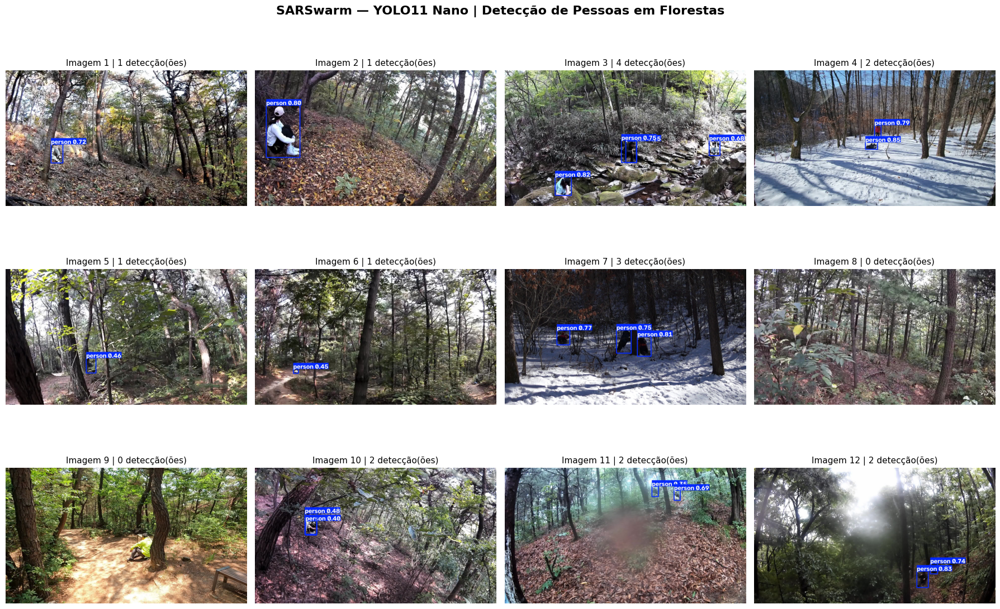


✅ Galeria gerada com sucesso!
Arquivo: /content/SARSwarm_Experimento02/resultados/deteccoes_dashboard/galeria_deteccoes.png
Imagens analisadas: 12
Total de detecções: 19


In [ ]:

from ultralytics import YOLO
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import random

BASE = Path("/content/SARSwarm_Experimento02")

caminho_modelo = (
    BASE / "resultados"
    / "treinamento_yolo11n"
    / "weights"
    / "best.pt"
)

pasta_teste = BASE / "images" / "test"
pasta_saida = BASE / "resultados" / "deteccoes_dashboard"
pasta_saida.mkdir(parents=True, exist_ok=True)

assert caminho_modelo.is_file(), "Modelo best.pt não encontrado!"
assert pasta_teste.is_dir(), "Imagens de teste não encontradas!"

imagens = sorted(
    p for p in pasta_teste.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
)

assert len(imagens) == 100, (
    f"Esperadas 100 imagens de teste; encontradas {len(imagens)}"
)

# Seleção reproduzível de 12 imagens
random.seed(42)
amostra = random.sample(imagens, 12)

modelo = YOLO(str(caminho_modelo))

print("=== SARSwarm — DETECÇÕES VISUAIS ===")
print("Modelo: YOLO11 Nano treinado")
print("Imagens selecionadas:", len(amostra))
print("Confiança mínima: 25%")
print("\nExecutando inferência...\n")

resultados = modelo.predict(
    source=[str(p) for p in amostra],
    imgsz=640,
    conf=0.25,
    device=0,
    save=True,
    project=str(BASE / "resultados"),
    name="deteccoes_dashboard",
    exist_ok=True,
    verbose=False
)

# Montar galeria com as imagens produzidas pelo modelo
fig, eixos = plt.subplots(3, 4, figsize=(18, 12))

for i, resultado in enumerate(resultados):
    eixo = eixos.flat[i]

    imagem_anotada = Image.open(
        pasta_saida / Path(resultado.path).name
    ).convert("RGB")

    eixo.imshow(imagem_anotada)
    eixo.axis("off")

    quantidade = len(resultado.boxes)
    eixo.set_title(
        f"Imagem {i + 1} | {quantidade} detecção(ões)",
        fontsize=11
    )

plt.suptitle(
    "SARSwarm — YOLO11 Nano | Detecção de Pessoas em Florestas",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

caminho_galeria = pasta_saida / "galeria_deteccoes.png"
plt.savefig(caminho_galeria, dpi=160, bbox_inches="tight")
plt.show()

print("\n✅ Galeria gerada com sucesso!")
print("Arquivo:", caminho_galeria)
print("Imagens analisadas:", len(resultados))
print(
    "Total de detecções:",
    sum(len(r.boxes) for r in resultados)
)

In [ ]:

from ultralytics import YOLO
from pathlib import Path
import numpy as np

BASE = Path("/content/SARSwarm_Experimento02")

modelo = YOLO(str(
    BASE / "resultados/treinamento_yolo11n/weights/best.pt"
))

def calcular_iou(a, b):
    x1 = max(a[0], b[0])
    y1 = max(a[1], b[1])
    x2 = min(a[2], b[2])
    y2 = min(a[3], b[3])

    intersecao = max(0, x2 - x1) * max(0, y2 - y1)

    area_a = max(0, a[2]-a[0]) * max(0, a[3]-a[1])
    area_b = max(0, b[2]-b[0]) * max(0, b[3]-b[1])

    uniao = area_a + area_b - intersecao

    return intersecao / uniao if uniao > 0 else 0

total_tp = 0
total_fp = 0
total_fn = 0

print("=== SARSwarm — ANÁLISE DAS 12 IMAGENS ===\n")

for numero, caminho in enumerate(amostra, start=1):
    resultado = modelo.predict(
        str(caminho),
        imgsz=640,
        conf=0.25,
        device=0,
        verbose=False
    )[0]

    # Ler caixas reais do arquivo YOLO
    caminho_label = BASE / "labels/test" / (
        caminho.stem + ".txt"
    )

    largura, altura = resultado.orig_shape[1], resultado.orig_shape[0]

    caixas_reais = []

    for linha in caminho_label.read_text().splitlines():
        classe, xc, yc, w, h = map(float, linha.split())

        caixas_reais.append([
            (xc - w/2) * largura,
            (yc - h/2) * altura,
            (xc + w/2) * largura,
            (yc + h/2) * altura
        ])

    # Caixas previstas, ordenadas por confiança
    caixas_previstas = resultado.boxes.xyxy.cpu().numpy()
    confiancas = resultado.boxes.conf.cpu().numpy()

    ordem = np.argsort(-confiancas)
    caixas_previstas = caixas_previstas[ordem]

    correspondencias = set()
    tp = 0
    fp = 0

    for prevista in caixas_previstas:
        melhor_iou = 0
        melhor_indice = -1

        for indice, real in enumerate(caixas_reais):
            if indice in correspondencias:
                continue

            iou = calcular_iou(prevista, real)

            if iou > melhor_iou:
                melhor_iou = iou
                melhor_indice = indice

        if melhor_iou >= 0.50:
            tp += 1
            correspondencias.add(melhor_indice)
        else:
            fp += 1

    fn = len(caixas_reais) - len(correspondencias)

    total_tp += tp
    total_fp += fp
    total_fn += fn

    print(
        f"Imagem {numero:02d} | "
        f"Reais: {len(caixas_reais)} | "
        f"TP: {tp} | FP: {fp} | FN: {fn}"
    )

print("\n=== RESUMO DA AMOSTRA ===")
print("Acertos (TP):", total_tp)
print("Falsos positivos (FP):", total_fp)
print("Falsos negativos (FN):", total_fn)

print("\n✅ Comparação concluída!")



=== SARSwarm — ANÁLISE DAS 12 IMAGENS ===

Imagem 01 | Reais: 1 | TP: 1 | FP: 0 | FN: 0
Imagem 02 | Reais: 1 | TP: 1 | FP: 0 | FN: 0
Imagem 03 | Reais: 3 | TP: 3 | FP: 1 | FN: 0
Imagem 04 | Reais: 2 | TP: 2 | FP: 0 | FN: 0
Imagem 05 | Reais: 1 | TP: 1 | FP: 0 | FN: 0
Imagem 06 | Reais: 1 | TP: 1 | FP: 0 | FN: 0
Imagem 07 | Reais: 3 | TP: 3 | FP: 0 | FN: 0
Imagem 08 | Reais: 1 | TP: 0 | FP: 0 | FN: 1
Imagem 09 | Reais: 1 | TP: 0 | FP: 0 | FN: 1
Imagem 10 | Reais: 1 | TP: 1 | FP: 1 | FN: 0
Imagem 11 | Reais: 2 | TP: 2 | FP: 0 | FN: 0
Imagem 12 | Reais: 2 | TP: 2 | FP: 0 | FN: 0

=== RESUMO DA AMOSTRA ===
Acertos (TP): 17
Falsos positivos (FP): 2
Falsos negativos (FN): 2

✅ Comparação concluída!


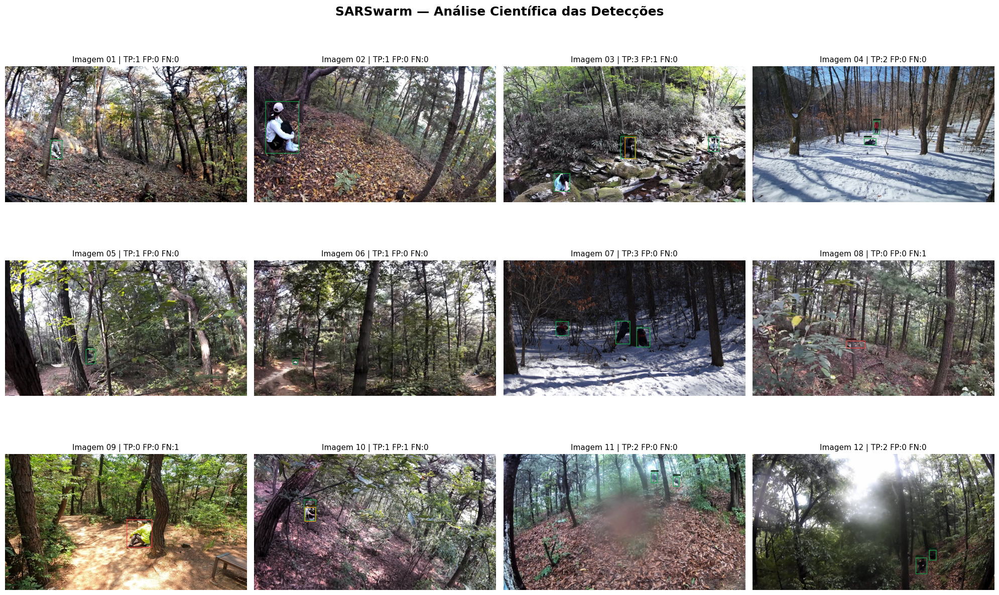


=== RESUMO ===
Acertos: 17
Falsos positivos: 2
Falsos negativos: 2
Galeria salva em: /content/SARSwarm_Experimento02/resultados/galeria_cientifica/galeria_cientifica.png

✅ Galeria científica concluída!


In [ ]:

from ultralytics import YOLO
from pathlib import Path
from PIL import Image, ImageDraw, ImageFont
import matplotlib.pyplot as plt
import numpy as np

BASE = Path("/content/SARSwarm_Experimento02")
SAIDA = BASE / "resultados" / "galeria_cientifica"
SAIDA.mkdir(parents=True, exist_ok=True)

modelo = YOLO(str(
    BASE / "resultados/treinamento_yolo11n/weights/best.pt"
))

fig, eixos = plt.subplots(3, 4, figsize=(20, 13))

totais = {"TP": 0, "FP": 0, "FN": 0}

for numero, caminho in enumerate(amostra, start=1):
    imagem = Image.open(caminho).convert("RGB")
    largura, altura = imagem.size
    desenho = ImageDraw.Draw(imagem)

    # Ler anotações reais
    label = BASE / "labels/test" / f"{caminho.stem}.txt"
    caixas_reais = []

    for linha in label.read_text().splitlines():
        classe, xc, yc, w, h = map(float, linha.split())
        caixas_reais.append([
            (xc - w/2) * largura,
            (yc - h/2) * altura,
            (xc + w/2) * largura,
            (yc + h/2) * altura
        ])

    # Executar detector
    resultado = modelo.predict(
        str(caminho),
        imgsz=640,
        conf=0.25,
        device=0,
        verbose=False
    )[0]

    caixas = resultado.boxes.xyxy.cpu().numpy()
    confiancas = resultado.boxes.conf.cpu().numpy()

    ordem = np.argsort(-confiancas)
    correspondencias = set()
    tp = fp = 0

    for indice_pred in ordem:
        prevista = caixas[indice_pred]
        melhor_iou = 0
        melhor_indice = -1

        for indice_real, real in enumerate(caixas_reais):
            if indice_real in correspondencias:
                continue

            iou = calcular_iou(prevista, real)

            if iou > melhor_iou:
                melhor_iou = iou
                melhor_indice = indice_real

        if melhor_iou >= 0.50:
            cor = "#16a34a"
            texto = f"ACERTO {confiancas[indice_pred]:.2f}"
            correspondencias.add(melhor_indice)
            tp += 1
        else:
            cor = "#f59e0b"
            texto = f"FALSO POSITIVO {confiancas[indice_pred]:.2f}"
            fp += 1

        desenho.rectangle(
            [tuple(prevista[:2]), tuple(prevista[2:])],
            outline=cor,
            width=5
        )

        x, y = int(prevista[0]), int(prevista[1])
        desenho.text(
            (x, max(0, y-18)),
            texto,
            fill=cor,
            stroke_width=2,
            stroke_fill="black"
        )

    # Destacar pessoas não encontradas
    fn = 0
    for indice_real, real in enumerate(caixas_reais):
        if indice_real not in correspondencias:
            desenho.rectangle(
                [tuple(real[:2]), tuple(real[2:])],
                outline="#ef4444",
                width=5
            )
            desenho.text(
                (int(real[0]), max(0, int(real[1])-18)),
                "NAO DETECTADA",
                fill="#ef4444",
                stroke_width=2,
                stroke_fill="black"
            )
            fn += 1

    totais["TP"] += tp
    totais["FP"] += fp
    totais["FN"] += fn

    imagem.save(SAIDA / f"imagem_{numero:02d}.png")

    eixo = eixos.flat[numero - 1]
    eixo.imshow(imagem)
    eixo.axis("off")
    eixo.set_title(
        f"Imagem {numero:02d} | TP:{tp} FP:{fp} FN:{fn}",
        fontsize=11
    )

plt.suptitle(
    "SARSwarm — Análise Científica das Detecções",
    fontsize=18,
    fontweight="bold"
)

plt.tight_layout()

galeria = SAIDA / "galeria_cientifica.png"
plt.savefig(galeria, dpi=160, bbox_inches="tight")
plt.show()

print("\n=== RESUMO ===")
print("Acertos:", totais["TP"])
print("Falsos positivos:", totais["FP"])
print("Falsos negativos:", totais["FN"])
print("Galeria salva em:", galeria)
print("\n✅ Galeria científica concluída!")


In [ ]:

from pathlib import Path
import pandas as pd
import json

BASE = Path("/content/SARSwarm_Experimento02")
RESULTADOS = BASE / "resultados"

# Carregar dados reais do experimento
csv_treinamento = (
    RESULTADOS / "treinamento_yolo11n" / "results.csv"
)
json_teste = (
    RESULTADOS / "avaliacao_teste" / "metricas_teste.json"
)

assert csv_treinamento.is_file(), "results.csv não encontrado!"
assert json_teste.is_file(), "metricas_teste.json não encontrado!"

df = pd.read_csv(csv_treinamento)
df.columns = df.columns.str.strip()

with open(json_teste, "r", encoding="utf-8") as f:
    metricas_teste = json.load(f)

# Histórico das épocas para gráficos interativos
historico = df.to_dict(orient="records")

# Análise complementar das 12 imagens
amostra_visual = {
    "imagens": 12,
    "pessoas_anotadas": 19,
    "deteccoes": 19,
    "verdadeiros_positivos": 17,
    "falsos_positivos": 2,
    "falsos_negativos": 2,
    "confianca_minima": 0.25,
    "iou_minimo": 0.50
}

dashboard = {
    "projeto": "SARSwarm",
    "experimento": "Experimento 02",
    "modelo": "YOLO11 Nano",
    "dataset": "etri/ForestPersons",
    "configuracao": {
        "imagens_treinamento": 500,
        "imagens_validacao": 100,
        "imagens_teste": 100,
        "epocas": 15,
        "resolucao": 640,
        "gpu": "NVIDIA Tesla T4"
    },
    "metricas_teste": metricas_teste,
    "amostra_visual": amostra_visual,
    "historico_treinamento": historico
}

saida = RESULTADOS / "dashboard_dados.json"

with open(saida, "w", encoding="utf-8") as f:
    json.dump(
        dashboard,
        f,
        indent=2,
        ensure_ascii=False,
        allow_nan=False
    )

print("=== SARSwarm — DADOS DO DASHBOARD ===")
print("Arquivo:", saida)
print("Épocas registradas:", len(historico))
print("Imagens de teste:", metricas_teste["imagens_teste"])
print("mAP@50:", f"{metricas_teste['mAP50']:.2%}")
print("Recall:", f"{metricas_teste['recall']:.2%}")
print("Acertos na galeria:", amostra_visual["verdadeiros_positivos"])

print("\n✅ Dados do dashboard organizados com sucesso!")


=== SARSwarm — DADOS DO DASHBOARD ===
Arquivo: /content/SARSwarm_Experimento02/resultados/dashboard_dados.json
Épocas registradas: 15
Imagens de teste: 100
mAP@50: 84.31%
Recall: 81.24%
Acertos na galeria: 17

✅ Dados do dashboard organizados com sucesso!
